## SECTION 2: Import Libraries

We import everything we need in one place:
- **Pandas / NumPy** – data handling
- **Matplotlib / Seaborn** – plots
- **Scikit-learn** – TF-IDF, Logistic Regression, metrics, train-test split
- **PyTorch** – tensors, datasets, training loop
- **Transformers** – BERT tokenizer and BERT model

We also check whether a **GPU** is available. Training BERT on a GPU is many times faster than on a CPU.

In [13]:
# Transformers is normally pre-installed in Colab. This line just makes sure.
!pip install -q transformers

In [14]:
import os
import re
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

from transformers import BertTokenizer, BertForSequenceClassification

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Fix random seeds so results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------- GPU detection ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device in use:", device)
if device.type == "cuda":
    print("GPU name     :", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU found. Go to Runtime → Change runtime type → T4 GPU for faster training.")
    print("   The notebook will automatically use a small CPU-friendly dataset.")

Device in use: cuda
GPU name     : Tesla T4


In [15]:
# ---------------- RUN SETTINGS (you can change these) ----------------
SMALL_DATASET     = True    # True = fast run, False = full dataset
SAMPLES_PER_CLASS = 2500    # used only if SMALL_DATASET = True  (2500 FAKE + 2500 REAL)
MAX_LEN           = 128     # maximum number of BERT tokens per article
EPOCHS            = 2       # BERT training epochs (2-3 recommended)
BATCH_SIZE        = 16
LEARNING_RATE     = 2e-5

# ---------------- CPU fallback ----------------
if device.type == "cpu":
    SMALL_DATASET     = True
    SAMPLES_PER_CLASS = 400   # 800 articles in total -> manageable on CPU
    EPOCHS            = 2

print("SMALL_DATASET    :", SMALL_DATASET)
print("SAMPLES_PER_CLASS:", SAMPLES_PER_CLASS if SMALL_DATASET else "all")
print("EPOCHS           :", EPOCHS)

SMALL_DATASET    : True
SAMPLES_PER_CLASS: 2500
EPOCHS           : 2


In [16]:
# Upload Fake.csv and True.csv (skipped automatically if the files are already uploaded)
if not (os.path.exists("Fake.csv") and os.path.exists("True.csv")):
    try:
        from google.colab import files
        print("Please select BOTH Fake.csv and True.csv")
        files.upload()
    except ImportError:
        print("Not running in Colab. Place Fake.csv and True.csv in the notebook folder.")

if not (os.path.exists("Fake.csv") and os.path.exists("True.csv")):
    raise FileNotFoundError("Fake.csv and/or True.csv not found. Please upload both files and re-run this cell.")
print("✅ Both files found.")

✅ Both files found.


In [17]:
# Load the two CSV files
fake_df = pd.read_csv("Fake.csv")
true_df = pd.read_csv("True.csv")

# Assign labels: FAKE = 0, REAL = 1
fake_df["label"] = 0
true_df["label"] = 1

# Combine both datasets into one DataFrame
df = pd.concat([fake_df, true_df], ignore_index=True)

# A readable label name, used only for plots
df["label_name"] = df["label"].map({0: "FAKE", 1: "REAL"})

print("Fake articles:", len(fake_df))
print("Real articles:", len(true_df))
print("Combined     :", len(df))
print("Columns      :", list(df.columns))

# First five rows
df.head()

Fake articles: 23481
Real articles: 21417
Combined     : 44898
Columns      : ['title', 'text', 'subject', 'date', 'label', 'label_name']


,title,text,subject,date,label,label_name
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0,FAKE
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0,FAKE
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0,FAKE
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0,FAKE
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0,FAKE


## SECTION 4: Exploratory Data Analysis (EDA)

Before building any model, we must **understand our data**. We will check:
- the size of the dataset,
- missing values and duplicate records,
- whether the classes are balanced,
- how long the articles are (this helps us choose BERT's maximum length).

In [18]:
# 4.1 Dataset shape and info
print("Dataset shape (rows, columns):", df.shape)
print()
df.info()

Dataset shape (rows, columns): (44898, 6)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   title       44898 non-null  object
 1   text        44898 non-null  object
 2   subject     44898 non-null  object
 3   date        44898 non-null  object
 4   label       44898 non-null  int64 
 5   label_name  44898 non-null  object
dtypes: int64(1), object(5)
memory usage: 2.1+ MB


In [19]:
# 4.2 Missing values
print("Missing values per column:")
print(df.isnull().sum())

# Some rows are not NaN but contain only blank text -> these are also useless
empty_text = (df["text"].fillna("").str.strip() == "").sum()
print("\nRows with empty / blank text:", empty_text)

Missing values per column:
title         0
text          0
subject       0
date          0
label         0
label_name    0
dtype: int64

Rows with empty / blank text: 631


In [20]:
# 4.3 Duplicate records
dup_count = df.duplicated(subset=["title", "text"]).sum()
print("Duplicate articles (same title and text):", dup_count)
print("Percentage of duplicates: {:.2f}%".format(100 * dup_count / len(df)))

Duplicate articles (same title and text): 5793
Percentage of duplicates: 12.90%


label_name
FAKE    23481
REAL    21417
Name: count, dtype: int64


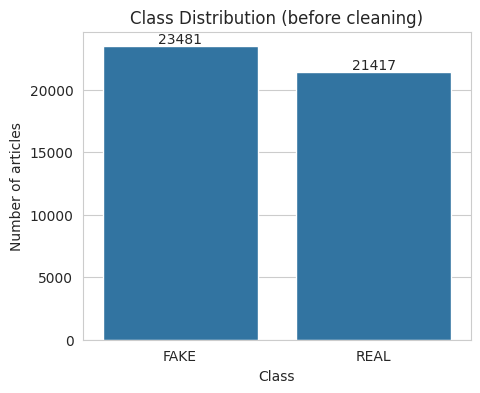

In [21]:
# 4.4 Class distribution
print(df["label_name"].value_counts())

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="label_name", order=["FAKE", "REAL"])
ax.bar_label(ax.containers[0])
plt.title("Class Distribution (before cleaning)")
plt.xlabel("Class")
plt.ylabel("Number of articles")
plt.show()

label_name                 FAKE          REAL
title_words count  23481.000000  21417.000000
            mean      14.732805      9.954475
            std        4.335099      1.700747
            min        1.000000      4.000000
            25%       12.000000      9.000000
            50%       14.000000     10.000000
            75%       17.000000     11.000000
            max       42.000000     20.000000
text_words  count  23481.000000  21417.000000
            mean     423.197905    385.640099
            std      408.388890    274.006204
            min        0.000000      0.000000
            25%      240.000000    148.000000
            50%      363.000000    359.000000
            75%      506.000000    525.000000
            max     8135.000000   5172.000000


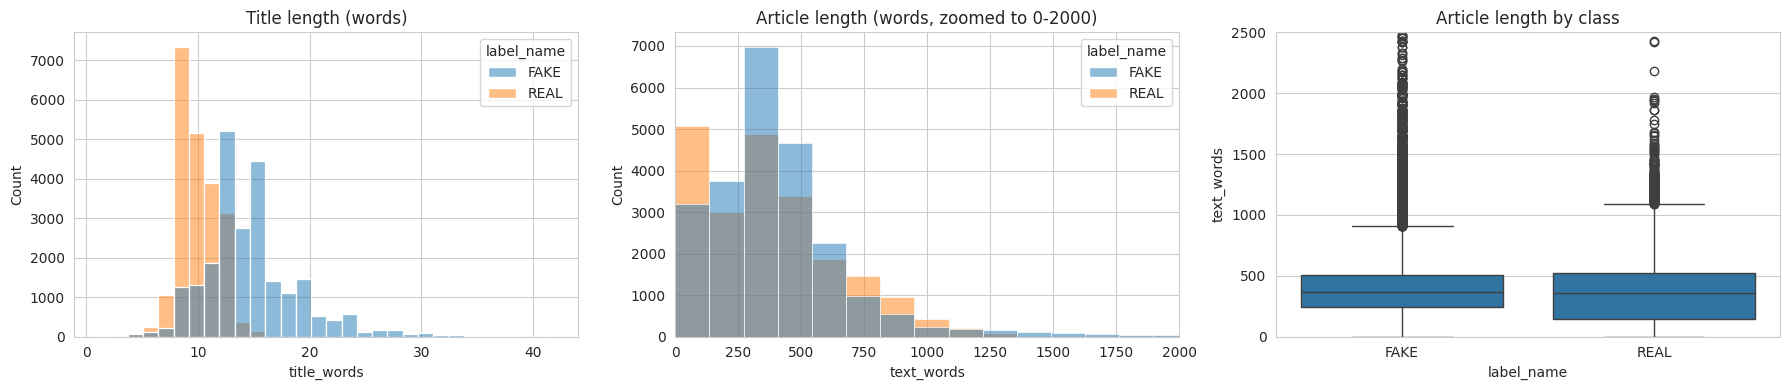

Most articles are much longer than 128 words, so BERT (max length 128) will read only
the beginning of each article. The title + first part of the text is usually enough.


In [22]:
# 4.5 News length analysis (number of words)
df["text_words"]  = df["text"].fillna("").str.split().str.len()
df["title_words"] = df["title"].fillna("").str.split().str.len()

print(df.groupby("label_name")[["title_words", "text_words"]].describe().T)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.histplot(data=df, x="title_words", hue="label_name", bins=30, ax=axes[0])
axes[0].set_title("Title length (words)")

sns.histplot(data=df, x="text_words", hue="label_name", bins=60, ax=axes[1])
axes[1].set_xlim(0, 2000)
axes[1].set_title("Article length (words, zoomed to 0-2000)")

sns.boxplot(data=df, x="label_name", y="text_words", ax=axes[2])
axes[2].set_ylim(0, 2500)
axes[2].set_title("Article length by class")

plt.tight_layout()
plt.show()

print("Most articles are much longer than 128 words, so BERT (max length 128) will read only")
print("the beginning of each article. The title + first part of the text is usually enough.")

In [23]:
# 4.6 Why we will DROP the 'subject' and 'date' columns
# Look at how 'subject' is distributed across the two classes:
print(pd.crosstab(df["subject"], df["label_name"]))

label_name       FAKE   REAL
subject                     
Government News  1570      0
Middle-east       778      0
News             9050      0
US_News           783      0
left-news        4459      0
politics         6841      0
politicsNews        0  11272
worldnews           0  10145


## SECTION 5: Data Preprocessing

Steps:
1. Remove missing / empty values.
2. Remove duplicate records.
3. Combine `title` and `text` into one column.
4. Clean unnecessary characters (URLs, HTML tags, symbols, source tags).
5. Encode labels (FAKE = 0, REAL = 1).
6. (Optional) take a balanced small sample for faster execution.
7. Split into **80 % train** and **20 % test**.

> We keep the same cleaning function for training **and** for custom predictions later, so the model always sees text in the same format.

In [24]:
# Step 1: remove missing values and empty texts
df_clean = df.dropna(subset=["title", "text"]).copy()
df_clean = df_clean[df_clean["text"].str.strip() != ""]
print("After removing missing/empty rows:", len(df_clean))

# Step 2: remove duplicate records
df_clean = df_clean.drop_duplicates(subset=["title", "text"])
print("After removing duplicates       :", len(df_clean))

After removing missing/empty rows: 44267
After removing duplicates       : 38658


In [25]:
# Step 3 & 4: clean the text and combine title + text

def clean_text(text):
    text = str(text).lower()                                   # lowercase (BERT uncased)
    text = re.sub(r"^[^()]{0,80}\(reuters\)\s*[-–—]?\s*", "", text)  # remove "CITY (Reuters) -" tag
    text = re.sub(r"\breuters\b", " ", text)                  # remove leftover 'reuters'
    text = re.sub(r"http\S+|www\.\S+", " ", text)              # remove URLs
    text = re.sub(r"pic\.twitter\.com\S+", " ", text)          # remove twitter picture links
    text = re.sub(r"<.*?>", " ", text)                         # remove HTML tags
    text = re.sub(r"[^a-z0-9\s.,!?'-]", " ", text)             # keep only letters, digits, basic punctuation
    text = re.sub(r"\s+", " ", text).strip()                   # remove extra spaces
    return text

# Clean title and text separately, then join them
df_clean["content"] = df_clean["title"].apply(clean_text) + " " + df_clean["text"].apply(clean_text)

# Remove articles that became very short or identical after cleaning
df_clean = df_clean[df_clean["content"].str.split().str.len() >= 10]
df_clean = df_clean.drop_duplicates(subset=["content"])

# Keep only the columns we need (this also drops 'subject' and 'date')
df_clean = df_clean[["content", "label"]].reset_index(drop=True)

print("Final number of articles:", len(df_clean))
print("\nExample of a cleaned article (first 300 characters):")
print(df_clean["content"][0][:300])

Final number of articles: 38378

Example of a cleaned article (first 300 characters):
donald trump sends out embarrassing new year s eve message this is disturbing donald trump just couldn t wish all americans a happy new year and leave it at that. instead, he had to give a shout out to his enemies, haters and the very dishonest fake news media. the former reality show star had just 


In [26]:
# Step 5: encode labels  (already numeric, we just make sure they are integers)
label_map = {0: "FAKE", 1: "REAL"}
df_clean["label"] = df_clean["label"].astype(int)
print("Label encoding:", label_map)
print(df_clean["label"].value_counts().rename(index=label_map))

# Step 6: optional balanced small dataset for faster execution
if SMALL_DATASET:
    n = min(SAMPLES_PER_CLASS, df_clean["label"].value_counts().min())
    df_clean = df_clean.groupby("label").sample(n=n, random_state=SEED)

# Shuffle the rows
df_clean = df_clean.sample(frac=1, random_state=SEED).reset_index(drop=True)
print("\nArticles used in this run:", len(df_clean))
print(df_clean["label"].value_counts().rename(index=label_map))

Label encoding: {0: 'FAKE', 1: 'REAL'}
label
REAL    20926
FAKE    17452
Name: count, dtype: int64

Articles used in this run: 5000
label
FAKE    2500
REAL    2500
Name: count, dtype: int64


In [27]:
# Step 7: Train-test split (80:20). 'stratify' keeps the FAKE/REAL ratio equal in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    df_clean["content"], df_clean["label"],
    test_size=0.2, random_state=SEED, stratify=df_clean["label"]
)

X_train = X_train.reset_index(drop=True)
X_test  = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test  = y_test.reset_index(drop=True)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# Leakage check: no article may appear in both train and test
overlap = set(X_train) & set(X_test)
print("Articles present in BOTH train and test:", len(overlap))
assert len(overlap) == 0, "Data leakage detected!"

Training samples: 4000
Testing samples : 1000
Articles present in BOTH train and test: 0


## SECTION 6: Baseline Model – TF-IDF + Logistic Regression

A **baseline** is a simple model that we use as a reference. If our deep learning model cannot beat (or at least match) a baseline, the added complexity is not worth it.

### How it works
- **TF-IDF** (Term Frequency – Inverse Document Frequency) converts each article into a vector of numbers. Words that are frequent in one article but rare overall get a high weight.
- **Logistic Regression** learns a weight for each word and predicts the probability of REAL vs FAKE.

> ✅ To avoid leakage, the TF-IDF vectorizer is **fitted only on the training data** (`fit_transform`) and then only **applied** to the test data (`transform`).

### Evaluation metrics (REAL = 1 is the "positive" class)
| Metric | Meaning |
|---|---|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of the articles predicted REAL, how many really are REAL |
| **Recall** | Of all REAL articles, how many did we find |
| **F1-score** | Harmonic mean of precision and recall |
| **Confusion matrix** | Table of correct and wrong predictions per class |

In [28]:
# Two small helper functions we will reuse for both models

def evaluate_model(y_true, y_pred):
    # Returns the four main metrics as a dictionary
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1-score":  f1_score(y_true, y_pred),
    }

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["FAKE", "REAL"], yticklabels=["FAKE", "REAL"])
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(title)
    plt.show()

# This dictionary will store the results of both models for Section 9
results = {}

In [29]:
# ---------- Train the baseline ----------
start_time = time.time()

tfidf = TfidfVectorizer(max_features=10000, stop_words="english", ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)     # learn vocabulary from TRAIN data only
X_test_tfidf  = tfidf.transform(X_test)          # only transform the TEST data

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

lr_train_time = time.time() - start_time
print("Logistic Regression training time: {:.2f} seconds".format(lr_train_time))

Logistic Regression training time: 11.72 seconds


Accuracy  : 0.9670
Precision : 0.9534
Recall    : 0.9820
F1-score  : 0.9675

Classification Report:

              precision    recall  f1-score   support

        FAKE       0.98      0.95      0.97       500
        REAL       0.95      0.98      0.97       500

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



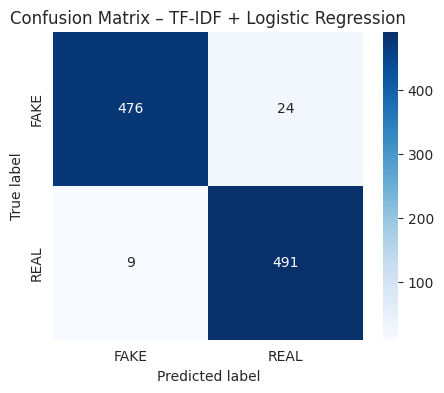

In [30]:
# ---------- Evaluate the baseline on the TEST set ----------
lr_pred = lr_model.predict(X_test_tfidf)

lr_scores = evaluate_model(y_test, lr_pred)
lr_scores["Training Time (sec)"] = lr_train_time
results["TF-IDF + Logistic Regression"] = lr_scores

for name, value in lr_scores.items():
    if name != "Training Time (sec)":
        print("{:<10}: {:.4f}".format(name, value))

print("\nClassification Report:\n")
print(classification_report(y_test, lr_pred, target_names=["FAKE", "REAL"]))

plot_confusion_matrix(y_test, lr_pred, "Confusion Matrix – TF-IDF + Logistic Regression")

In [31]:
# Which words does Logistic Regression rely on most? (helps us understand the model)
words = np.array(tfidf.get_feature_names_out())
coefs = lr_model.coef_[0]

print("Top 10 words pointing to FAKE:", list(words[np.argsort(coefs)[:10]]))
print("Top 10 words pointing to REAL:", list(words[np.argsort(coefs)[-10:]]))

Top 10 words pointing to FAKE: ['video', 'just', 'hillary', 'image', 'featured', 'featured image', 'gop', 'like', 'obama', 'watch']
Top 10 words pointing to REAL: ['government', 'friday', 'presidential', 'thursday', 'minister', 'republican', 'president donald', 'wednesday', 'tuesday', 'said']


## SECTION 7: BERT Deep Learning Model

### What is BERT?
**BERT** (*Bidirectional Encoder Representations from Transformers*) is a language model pre-trained by Google on huge amounts of text. It already "understands" English grammar and word meaning. We use **fine-tuning**: we take the pre-trained `bert-base-uncased` and train it a little more on our fake-news data.

### Steps in this section
1. Load the **BERT tokenizer** – it converts text into token IDs (numbers).
2. **Tokenize** all articles (max length **128** tokens; longer text is cut, shorter text is padded).
3. Build a custom **PyTorch `Dataset`** and **`DataLoader`s** to feed data in batches.
4. Load **`BertForSequenceClassification`** with 2 output labels (FAKE / REAL).
5. Train with the **AdamW** optimizer and display the training loss.
6. Evaluate on the test set and plot the confusion matrix.

> 💡 When you load the model you will see a warning that some weights are *"newly initialized"*. This is **normal**: it is the new classification layer on top of BERT that we are about to train.

In [32]:
# 7.1 Load the BERT tokenizer
MODEL_NAME = "bert-base-uncased"
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

# Quick demo: what does the tokenizer do?
demo = "Fake news spreads quickly."
print("Text      :", demo)
print("Tokens    :", tokenizer.tokenize(demo))
print("Token IDs :", tokenizer.encode(demo))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Text      : Fake news spreads quickly.
Tokens    : ['fake', 'news', 'spreads', 'quickly', '.']
Token IDs : [101, 8275, 2739, 20861, 2855, 1012, 102]


In [33]:
# 7.2 Tokenize the training and test articles (this may take 1-2 minutes)
train_encodings = tokenizer(X_train.tolist(), truncation=True, padding="max_length", max_length=MAX_LEN)
test_encodings  = tokenizer(X_test.tolist(),  truncation=True, padding="max_length", max_length=MAX_LEN)

print("Each article is now a list of", len(train_encodings["input_ids"][0]), "token IDs")
print("Keys:", list(train_encodings.keys()))

Each article is now a list of 128 token IDs
Keys: ['input_ids', 'token_type_ids', 'attention_mask']


In [34]:
# 7.3 Custom PyTorch Dataset
class NewsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Convert one article into PyTorch tensors
        item = {key: torch.tensor(values[idx]) for key, values in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx])
        return item

train_dataset = NewsDataset(train_encodings, y_train.tolist())
test_dataset  = NewsDataset(test_encodings,  y_test.tolist())

# 7.4 DataLoaders (feed the data to the model in batches)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)

print("Training batches:", len(train_loader))
print("Testing batches :", len(test_loader))

Training batches: 250
Testing batches : 32


In [35]:
# 7.5 Load BERT for classification (2 labels: FAKE = 0, REAL = 1)
model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model.to(device)

# 7.6 Optimizer: AdamW
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)

print("Model loaded on:", device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded on: cuda


In [36]:
# 7.7 Training loop
epoch_losses = []
bert_start = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for step, batch in enumerate(train_loader):
        batch = {key: value.to(device) for key, value in batch.items()}

        optimizer.zero_grad()              # 1. clear old gradients
        outputs = model(**batch)           # 2. forward pass (loss is computed because labels are given)
        loss = outputs.loss
        loss.backward()                    # 3. backward pass (compute gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # keeps training stable
        optimizer.step()                   # 4. update the weights

        running_loss += loss.item()

        if (step + 1) % 50 == 0:
            print("Epoch {}/{} | Step {}/{} | Loss: {:.4f}".format(
                epoch + 1, EPOCHS, step + 1, len(train_loader), loss.item()))

    avg_loss = running_loss / len(train_loader)
    epoch_losses.append(avg_loss)
    print(">>> Epoch {} finished | Average training loss: {:.4f}\n".format(epoch + 1, avg_loss))

bert_train_time = time.time() - bert_start
print("BERT training time: {:.2f} seconds ({:.1f} minutes)".format(bert_train_time, bert_train_time / 60))

Epoch 1/2 | Step 50/250 | Loss: 0.2757
Epoch 1/2 | Step 100/250 | Loss: 0.0082
Epoch 1/2 | Step 150/250 | Loss: 0.0070
Epoch 1/2 | Step 200/250 | Loss: 0.1806
Epoch 1/2 | Step 250/250 | Loss: 0.0023
>>> Epoch 1 finished | Average training loss: 0.1935

Epoch 2/2 | Step 50/250 | Loss: 0.0017
Epoch 2/2 | Step 100/250 | Loss: 0.0931
Epoch 2/2 | Step 150/250 | Loss: 0.0851
Epoch 2/2 | Step 200/250 | Loss: 0.0015
Epoch 2/2 | Step 250/250 | Loss: 0.0005
>>> Epoch 2 finished | Average training loss: 0.0402

BERT training time: 197.56 seconds (3.3 minutes)


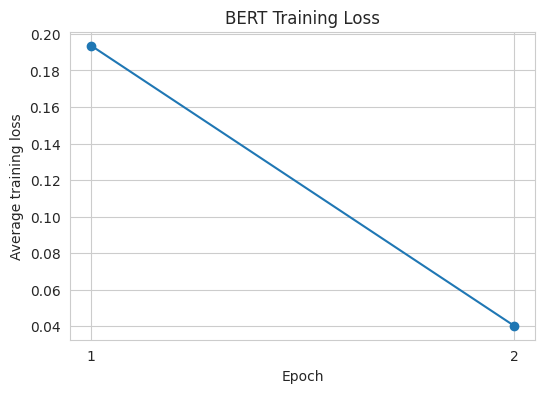

In [37]:
# 7.8 Plot the training loss
plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), epoch_losses, marker="o")
plt.xticks(range(1, EPOCHS + 1))
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("BERT Training Loss")
plt.grid(True)
plt.show()

Accuracy  : 0.9820
Precision : 0.9671
Recall    : 0.9980
F1-score  : 0.9823

Classification Report:

              precision    recall  f1-score   support

        FAKE       1.00      0.97      0.98       500
        REAL       0.97      1.00      0.98       500

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000



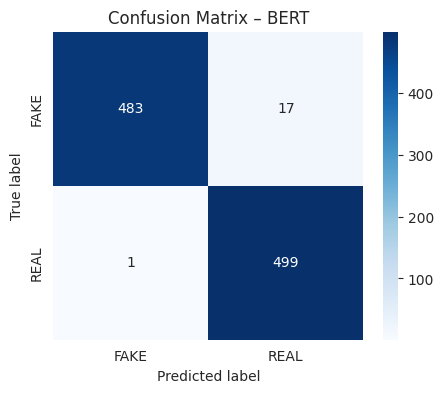

In [38]:
# 7.9 Evaluate BERT on the TEST set (the model has never seen this data)
model.eval()
bert_pred = []

with torch.no_grad():
    for batch in test_loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        outputs = model(input_ids=batch["input_ids"],
                        attention_mask=batch["attention_mask"],
                        token_type_ids=batch["token_type_ids"])
        predictions = torch.argmax(outputs.logits, dim=1)
        bert_pred.extend(predictions.cpu().numpy())

bert_pred = np.array(bert_pred)

bert_scores = evaluate_model(y_test, bert_pred)
bert_scores["Training Time (sec)"] = bert_train_time
results["BERT"] = bert_scores

for name, value in bert_scores.items():
    if name != "Training Time (sec)":
        print("{:<10}: {:.4f}".format(name, value))

print("\nClassification Report:\n")
print(classification_report(y_test, bert_pred, target_names=["FAKE", "REAL"]))

plot_confusion_matrix(y_test, bert_pred, "Confusion Matrix – BERT")

## SECTION 8: Custom News Prediction

Now we use the trained BERT model on **new text**. The function below:
1. cleans the input with the **same** `clean_text()` function,
2. tokenizes it with the BERT tokenizer (max length 128),
3. passes it through the trained model,
4. converts the raw outputs (*logits*) into probabilities using **softmax**,
5. prints the predicted class (FAKE / REAL) and the model's **confidence**.

> ℹ️ The model was trained on English political/world news from roughly 2016–2018. It may be less reliable for other topics or very short headlines. Confidence shows how sure the model is, **not** whether it is truly correct.

In [39]:
def predict_news(text, show=True):
    # 1. preprocess
    cleaned = clean_text(text)

    # 2. tokenize
    enc = tokenizer(cleaned, truncation=True, padding="max_length",
                    max_length=MAX_LEN, return_tensors="pt")
    enc = {key: value.to(device) for key, value in enc.items()}

    # 3. pass through the trained BERT
    model.eval()
    with torch.no_grad():
        logits = model(**enc).logits

    # 4. probabilities and prediction
    probs = torch.softmax(logits, dim=1)[0]
    pred_id = int(torch.argmax(probs))
    label = "REAL" if pred_id == 1 else "FAKE"
    confidence = probs[pred_id].item() * 100

    if show:
        print("News       :", text[:150] + ("..." if len(text) > 150 else ""))
        print("Prediction :", label)
        print("Confidence : {:.2f}%".format(confidence))
        print("P(FAKE) = {:.2f}% | P(REAL) = {:.2f}%".format(probs[0].item() * 100, probs[1].item() * 100))
        print("-" * 70)
    return label, confidence

In [40]:
# Demonstration on sample news inputs (written by us - NOT taken from the dataset)
sample_news = [
    "The Senate passed a bipartisan spending bill on Tuesday after weeks of negotiations, sending the measure to the House for a final vote, officials said.",
    "BREAKING: Secret documents leaked online prove the president plans to cancel the next election, and the mainstream media is hiding it from you!!!",
    "The central bank kept interest rates unchanged on Wednesday and said it would keep watching inflation data before deciding on any further moves.",
    "Shocking truth: scientists say drinking hot lemon water cures every disease, but big pharma doesn't want you to know!",
]

for news in sample_news:
    predict_news(news)

News       : The Senate passed a bipartisan spending bill on Tuesday after weeks of negotiations, sending the measure to the House for a final vote, officials said...
Prediction : REAL
Confidence : 99.93%
P(FAKE) = 0.07% | P(REAL) = 99.93%
----------------------------------------------------------------------
News       : BREAKING: Secret documents leaked online prove the president plans to cancel the next election, and the mainstream media is hiding it from you!!!
Prediction : FAKE
Confidence : 99.93%
P(FAKE) = 99.93% | P(REAL) = 0.07%
----------------------------------------------------------------------
News       : The central bank kept interest rates unchanged on Wednesday and said it would keep watching inflation data before deciding on any further moves.
Prediction : REAL
Confidence : 99.94%
P(FAKE) = 0.06% | P(REAL) = 99.94%
----------------------------------------------------------------------
News       : Shocking truth: scientists say drinking hot lemon water cures every dis

### ✍️ Try your own news
Edit the text inside the quotes below and run the cell. (We use a variable instead of `input()` so that "Run all" is never blocked waiting for typing.)

In [41]:
my_news = "Type or paste any news headline or full article here."

predict_news(my_news)

# Optional: for a live typing box, remove the '#' from the next two lines
# my_news = input("Enter a news headline or article: ")
# predict_news(my_news)

News       : Type or paste any news headline or full article here.
Prediction : REAL
Confidence : 63.80%
P(FAKE) = 36.20% | P(REAL) = 63.80%
----------------------------------------------------------------------


('REAL', 63.804370164871216)

## SECTION 9: Model Comparison

We now put the results of both models side by side. All numbers come directly from the evaluation on the **same test set** in the cells above.

> ⚠️ **Training time** is not a perfectly fair comparison: Logistic Regression runs on the CPU, while BERT runs on the device selected in Section 2 (GPU if available). It still shows the real cost of each approach in this run.

In [42]:
# Comparison table
results_df = pd.DataFrame(results).T.reset_index()
results_df = results_df.rename(columns={"index": "Model"})
results_df = results_df[["Model", "Accuracy", "Precision", "Recall", "F1-score", "Training Time (sec)"]]
results_df[["Accuracy", "Precision", "Recall", "F1-score"]] = results_df[["Accuracy", "Precision", "Recall", "F1-score"]].round(4)
results_df["Training Time (sec)"] = results_df["Training Time (sec)"].round(2)

results_df

,Model,Accuracy,Precision,Recall,F1-score,Training Time (sec)
0,TF-IDF + Logistic Regression,0.967,0.9534,0.982,0.9675,11.72
1,BERT,0.982,0.9671,0.998,0.9823,197.56


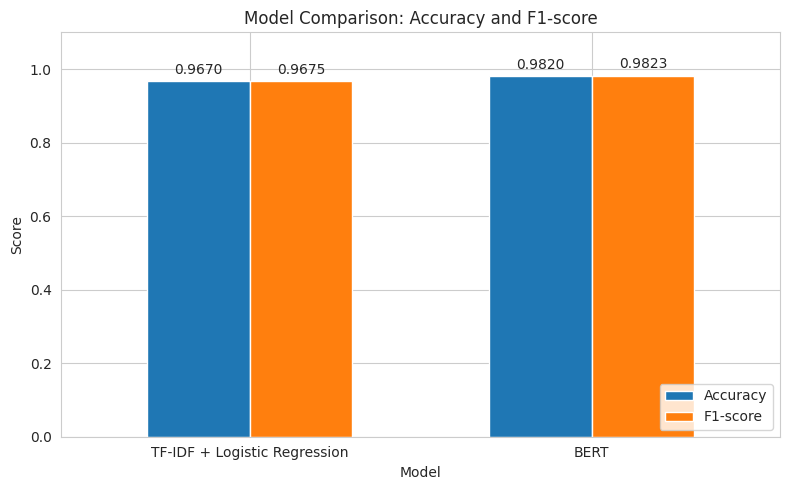

In [43]:
# Bar chart: Accuracy and F1-score
plot_df = results_df.set_index("Model")[["Accuracy", "F1-score"]]

ax = plot_df.plot(kind="bar", figsize=(8, 5), rot=0, width=0.6)
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", padding=3)

ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("Model Comparison: Accuracy and F1-score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [44]:
# Automatic summary written from YOUR actual results (nothing is hard-coded)
lr  = results["TF-IDF + Logistic Regression"]
brt = results["BERT"]

print("Test-set results from this run")
print("-" * 50)
print("Logistic Regression  -> Accuracy {:.4f} | F1 {:.4f} | Time {:.1f}s".format(lr["Accuracy"], lr["F1-score"], lr["Training Time (sec)"]))
print("BERT                 -> Accuracy {:.4f} | F1 {:.4f} | Time {:.1f}s".format(brt["Accuracy"], brt["F1-score"], brt["Training Time (sec)"]))
print("-" * 50)

if brt["F1-score"] > lr["F1-score"]:
    print("BERT achieved the higher F1-score by {:.4f}.".format(brt["F1-score"] - lr["F1-score"]))
elif brt["F1-score"] < lr["F1-score"]:
    print("Logistic Regression achieved the higher F1-score by {:.4f}.".format(lr["F1-score"] - brt["F1-score"]))
else:
    print("Both models achieved the same F1-score.")

print("BERT took {:.1f}x the training time of Logistic Regression.".format(brt["Training Time (sec)"] / max(lr["Training Time (sec)"], 1e-6)))

Test-set results from this run
--------------------------------------------------
Logistic Regression  -> Accuracy 0.9670 | F1 0.9675 | Time 11.7s
BERT                 -> Accuracy 0.9820 | F1 0.9823 | Time 197.6s
--------------------------------------------------
BERT achieved the higher F1-score by 0.0148.
BERT took 16.9x the training time of Logistic Regression.


## SECTION 10: Conclusion and Future Scope

### Project achievements
- Built a complete fake-news classifier pipeline (loading → EDA → cleaning → modelling → evaluation → prediction) in a **single Colab notebook**, with **no external API**.
- Trained and evaluated two models on the same, leakage-controlled train/test split: **TF-IDF + Logistic Regression** and a fine-tuned **BERT**.
- Removed known shortcuts in the dataset (`subject` column, "(Reuters)" tag, duplicates) so scores are more honest.
- Created a reusable prediction function that returns FAKE/REAL with a confidence score.
- Saved the trained model so it can be reused without retraining.

> 📊 *Look at the auto-generated summary and comparison table above for the exact numbers from your run.* On this popular dataset, both models often score very high, so the gap between them may be small. **Do not claim that BERT is "much better" unless your own results show it.**

### Why BERT performs differently from traditional ML
- **Logistic Regression + TF-IDF** treats an article as a *bag of words*: it counts words and ignores word order and context. It is fast, simple and easy to interpret.
- **BERT** reads the whole sentence **in both directions** using self-attention, so the same word gets a different representation depending on its context (e.g. *"bank"* of a river vs. a money *bank*). It also starts with **pre-trained language knowledge**.
- The price of BERT is **more computation, more memory, longer training** and lower interpretability.

### Limitations
- The dataset is mostly **US political news from 2016–2018**; the model may not generalise to other topics, languages or newer events.
- The model detects **writing style and patterns**, not the **factual truth**. It cannot verify facts against the real world.
- BERT reads only the **first 128 tokens**; important information later in a long article is ignored.
- For speed we may have used a **small sample** of the dataset, and only **2–3 epochs** without hyper-parameter tuning.
- A single train/test split was used (no cross-validation), so results can vary slightly between runs.
- Residual style differences between the sources (e.g. capital letters, writing tone) may still make the task easier than real-world fake news detection.

### Future improvements
- Train on the **full dataset** and more epochs; use a learning-rate scheduler and a separate validation set.
- Try larger/better models (RoBERTa, DistilBERT for speed, DeBERTa).
- Use **longer inputs** (512 tokens, or chunking).
- Test on a **different dataset** (e.g. LIAR, FakeNewsNet) to check generalisation.
- Add **explainability** (LIME / SHAP / attention visualisation) to show *why* an article was flagged.
- Combine text with other signals: source credibility, author, social-media propagation, fact-checking databases.
- Build a small web app (e.g. Streamlit / Gradio) around the saved model.

## 💾 Save the Trained BERT Model

We save the fine-tuned model **and** the tokenizer to a folder. They can be loaded later with `from_pretrained()`, with no retraining needed.

In [45]:
SAVE_DIR = "saved_bert_fake_news"

model.save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)

print("Model saved in folder:", SAVE_DIR)
print("Files:", os.listdir(SAVE_DIR))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved in folder: saved_bert_fake_news
Files: ['tokenizer_config.json', 'config.json', 'tokenizer.json', 'model.safetensors']


In [46]:
# Optional: zip the folder and download it to your computer
import shutil
shutil.make_archive("saved_bert_fake_news", "zip", SAVE_DIR)
print("Created saved_bert_fake_news.zip")

try:
    from google.colab import files
    files.download("saved_bert_fake_news.zip")
except ImportError:
    print("Not in Colab - the zip file is in the current folder.")

Created saved_bert_fake_news.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
# Optional: reload the saved model to prove that saving worked
loaded_tokenizer = BertTokenizer.from_pretrained(SAVE_DIR)
loaded_model = BertForSequenceClassification.from_pretrained(SAVE_DIR).to(device)
loaded_model.eval()

test_text = clean_text(sample_news[0])
enc = loaded_tokenizer(test_text, truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
enc = {key: value.to(device) for key, value in enc.items()}
with torch.no_grad():
    probs = torch.softmax(loaded_model(**enc).logits, dim=1)[0]

print("Reloaded model prediction:", "REAL" if probs.argmax().item() == 1 else "FAKE",
      "| confidence {:.2f}%".format(probs.max().item() * 100))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reloaded model prediction: REAL | confidence 99.93%
